In [35]:
library(tidyverse)
library(corrplot)
library(psych)
library(rstatix)
library(factoextra)
library(effectsize)

In [36]:
red_wine <- read_delim("/kaggle/input/datasets/rddelarosa/sa-wines/winequality-red.csv", delim = ";") %>%
  mutate(color = "Red")

white_wine <- read_delim("/kaggle/input/datasets/rddelarosa/sa-wines/winequality-white.csv", delim = ";") %>%
  mutate(color = "White")

wine_data <- bind_rows(red_wine, white_wine) %>%
  mutate(color = as.factor(color))

names(wine_data) <- gsub(" ", ".", names(wine_data))

Rows: 1599 Columns: 12
── Column specification ────────────────────────────────────────────────────────
Delimiter: ";"
dbl (12): fixed acidity, volatile acidity, citric acid, residual sugar, chlo...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 4898 Columns: 12
── Column specification ────────────────────────────────────────────────────────
Delimiter: ";"
dbl (12): fixed acidity, volatile acidity, citric acid, residual sugar, chlo...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [37]:
str(wine_data)
dim(wine_data) 
sum(is.na(wine_data)) 
sum(duplicated(wine_data))

tibble [6,497 × 13] (S3: tbl_df/tbl/data.frame)
 $ fixed.acidity       : num [1:6497] 7.4 7.8 7.8 11.2 7.4 7.4 7.9 7.3 7.8 7.5 ...
 $ volatile.acidity    : num [1:6497] 0.7 0.88 0.76 0.28 0.7 0.66 0.6 0.65 0.58 0.5 ...
 $ citric.acid         : num [1:6497] 0 0 0.04 0.56 0 0 0.06 0 0.02 0.36 ...
 $ residual.sugar      : num [1:6497] 1.9 2.6 2.3 1.9 1.9 1.8 1.6 1.2 2 6.1 ...
 $ chlorides           : num [1:6497] 0.076 0.098 0.092 0.075 0.076 0.075 0.069 0.065 0.073 0.071 ...
 $ free.sulfur.dioxide : num [1:6497] 11 25 15 17 11 13 15 15 9 17 ...
 $ total.sulfur.dioxide: num [1:6497] 34 67 54 60 34 40 59 21 18 102 ...
 $ density             : num [1:6497] 0.998 0.997 0.997 0.998 0.998 ...
 $ pH                  : num [1:6497] 3.51 3.2 3.26 3.16 3.51 3.51 3.3 3.39 3.36 3.35 ...
 $ sulphates           : num [1:6497] 0.56 0.68 0.65 0.58 0.56 0.56 0.46 0.47 0.57 0.8 ...
 $ alcohol             : num [1:6497] 9.4 9.8 9.8 9.8 9.4 9.4 9.4 10 9.5 10.5 ...
 $ quality             : num [1:6497] 5 5 5

[1] 6497   13

[1] 0

[1] 1177

## Part A – Data Preparation and Exploratory Analysis


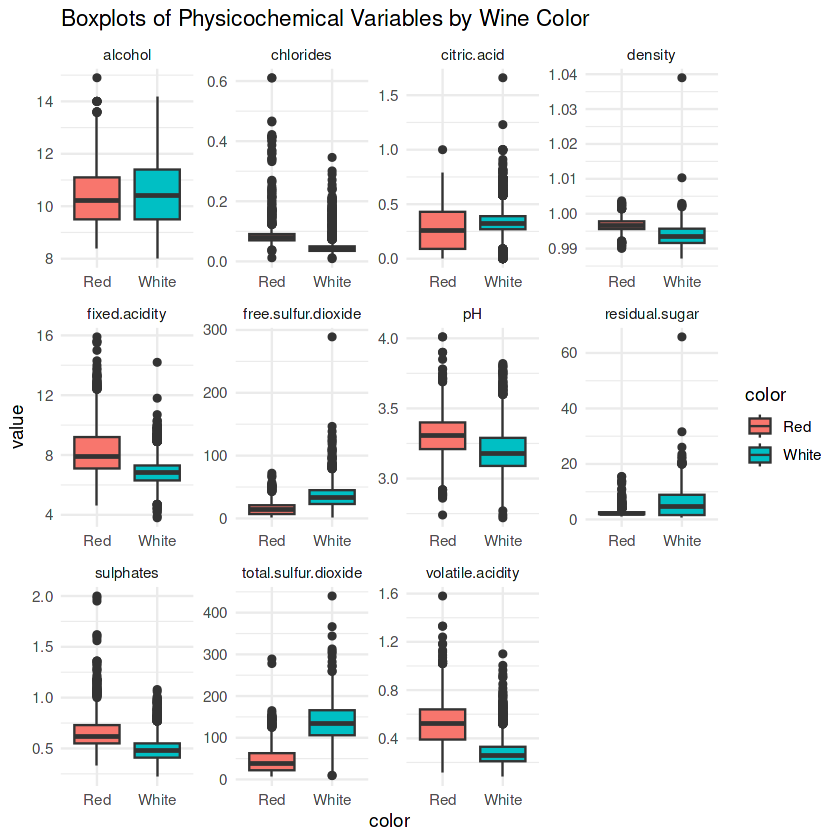

In [38]:
# Remove duplicates 
wine_data <- unique(wine_data)

# Examine univariate outliers using boxplots
wine_data %>%
  select(-quality) %>%
  pivot_longer(cols = -color, names_to = "variable", values_to = "value") %>%
  ggplot(aes(x = color, y = value, fill = color)) +
  geom_boxplot() +
  facet_wrap(~variable, scales = "free") +
  theme_minimal() +
  labs(title = "Boxplots of Physicochemical Variables by Wine Color")

ggsave("boxplots.png", width = 10, height = 8, dpi = 300)

In [39]:
# Descriptive statistics
describeBy(wine_data %>% select(-color), group = wine_data$color)


 Descriptive statistics by group 
group: Red
                     vars    n  mean    sd median trimmed   mad  min    max
fixed.acidity           1 1359  8.31  1.74   7.90    8.15  1.48 4.60  15.90
volatile.acidity        2 1359  0.53  0.18   0.52    0.52  0.19 0.12   1.58
citric.acid             3 1359  0.27  0.20   0.26    0.26  0.25 0.00   1.00
residual.sugar          4 1359  2.52  1.35   2.20    2.26  0.44 0.90  15.50
chlorides               5 1359  0.09  0.05   0.08    0.08  0.01 0.01   0.61
free.sulfur.dioxide     6 1359 15.89 10.45  14.00   14.60 10.38 1.00  72.00
total.sulfur.dioxide    7 1359 46.83 33.41  38.00   42.13 28.17 6.00 289.00
density                 8 1359  1.00  0.00   1.00    1.00  0.00 0.99   1.00
pH                      9 1359  3.31  0.16   3.31    3.31  0.15 2.74   4.01
sulphates              10 1359  0.66  0.17   0.62    0.64  0.12 0.33   2.00
alcohol                11 1359 10.43  1.08  10.20   10.32  1.04 8.40  14.90
quality                12 1359  5.62  0.82

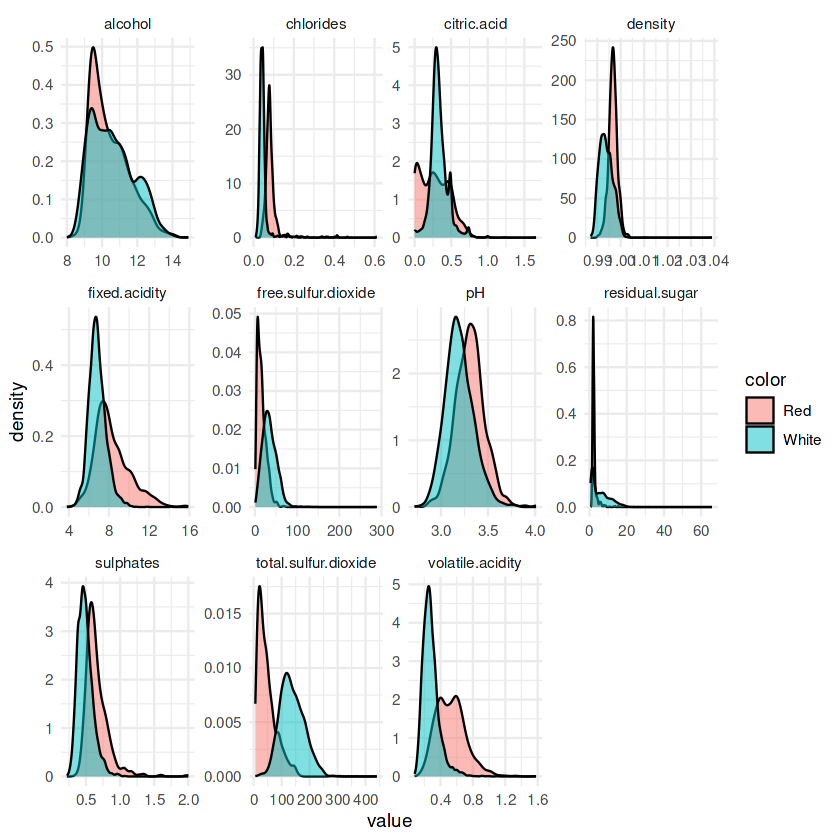

pdf 
  2

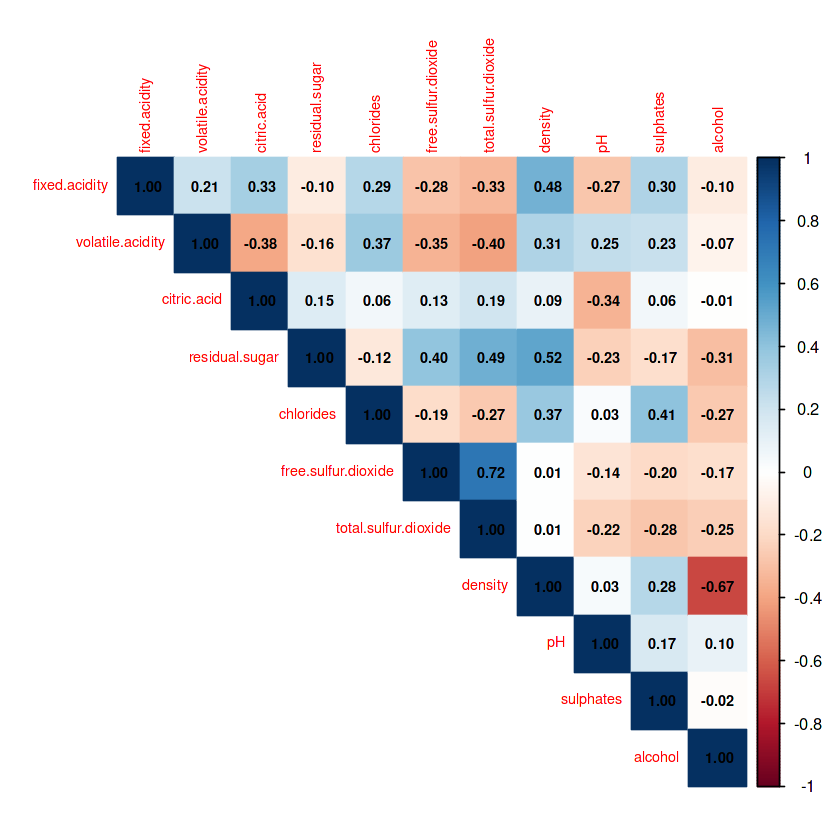

In [40]:
# Distributions
wine_data %>%
  select(-quality) %>%
  pivot_longer(cols = -color, names_to = "variable", values_to = "value") %>%
  ggplot(aes(x = value, fill = color)) +
  geom_density(alpha = 0.5) +
  facet_wrap(~variable, scales = "free") +
  theme_minimal()

ggsave("distributions_density.png", width = 10, height = 8, dpi = 300)

#Correlation matrix
numeric_vars <- wine_data %>% select(-color, -quality)
cor_matrix <- cor(numeric_vars)
corrplot(cor_matrix, method = "color", type = "upper", addCoef.col = "black", tl.cex = 0.7, number.cex = 0.7)

png("correlation_matrix.png", width = 800, height = 800, res = 120)
corrplot(cor_matrix, method = "color", type = "upper", addCoef.col = "black", tl.cex = 0.7, number.cex = 0.7)
dev.off()

* **Which variables appear most variable?**
The sulfur dioxide variables exhibit the most variability by a wide margin. `total_sulfur_dioxide` has a standard deviation of 33.41 in red wines and 43.13 in white wines. `free_sulfur_dioxide` also shows high variability, with a standard deviation of 10.45 in reds and 17.21 in whites. Additionally, `residual_sugar` shows substantial variability, particularly in white wines (SD = 4.86).


* **Which variables appear strongly correlated?**
According to the correlation matrix, the strongest relationships are:
    * `free_sulfur_dioxide` and `total_sulfur_dioxide` show a strong positive correlation (r = 0.72).
    * `density` and `alcohol` show a strong negative correlation (r = -0.67).
    * `residual_sugar` and `density` show a moderate positive correlation (r = 0.52).
    * `fixed_acidity` and `density` show a moderate positive correlation (r = 0.48).

* **Are there noticeable differences between red and white wines?**
Yes, there are distinct differences visible in both the boxplots and density plots. Red wines tend to have higher levels of `volatile_acidity`, `fixed_acidity`, `chlorides`, and `sulphates`. Conversely, white wines generally exhibit higher levels of `total_sulfur_dioxide`, `free_sulfur_dioxide`, and `residual_sugar`.


* **Are there potential outliers or unusual observations?**
Yes, the boxplots reveal numerous potential univariate outliers across almost all variables. There are many individual data points plotted well above the upper whiskers for variables like `residual_sugar` (particularly in white wines), `chlorides` (particularly in red wines), and `sulphates`.


* **Are there variables that may require special consideration before PCA or EFA?**
Yes, because the variables are measured on drastically different scales, they require standardization before PCA or EFA. For example, `total_sulfur_dioxide` has means ranging from ~46 to 137, while variables like `density`, `chlorides`, and `volatile_acidity` have means at or below 1.0. If the data is not standardized, variables with naturally larger scales and variances (like the sulfur dioxides) will artificially dominate the principal components and latent factors.

## Part B – Multivariate Analysis of Variance (MANOVA)

* **$H_{0}$ (Null Hypothesis):** The mean vector of the selected physicochemical variables is the same for red and white wines.

* **$H_{1}$ (Alternative Hypothesis):** The mean vectors differ between red and white wines.

These four variables (`fixed_acidity`, `volatile_acidity`, `residual_sugar`, and `chlorides`) were selected based on the exploratory data analysis and their suitability for MANOVA.

1. **Visual Differences:** The exploratory boxplots revealed distinct median differences and non-overlapping interquartile ranges between red and white wines for these specific features.

2. **Chemical Diversity:** They represent fundamentally distinct chemical properties of the wine: baseline tartness (fixed acidity), potential spoilage/vinegar taste (volatile acidity), sweetness (residual sugar), and salt/mineral content (chlorides).

4. **Avoiding Multicollinearity:** Selecting these four avoids the highly correlated variable pairs identified in the correlation matrix (such as `density` with `alcohol`, or `free_sulfur_dioxide` with `total_sulfur_dioxide`). Avoiding highly correlated dependent variables is important to satisfy the MANOVA assumption of reasonable relationships among dependent variables without severe multicollinearity.

In [41]:
# Define DV matrix
dvs <- as.matrix(wine_data %>% select(fixed.acidity, volatile.acidity, residual.sugar, chlorides))

# Assess MANOVA Assumptions
box_m(dvs, wine_data$color)

# Conduct MANOVA
manova_model <- manova(dvs ~ color, data = wine_data)
summary(manova_model, test = "Pillai") # Pillai's trace is robust to assumption violations

# Follow-up univariate ANOVAs
summary.aov(manova_model)

# Effect size (Partial Eta Squared)
eta_squared(manova_model)

statistic,p.value,parameter,method
<dbl>,<dbl>,<dbl>,<chr>
5342.208,0,10,Box's M-test for Homogeneity of Covariance Matrices


            Df  Pillai approx F num Df den Df    Pr(>F)    
color        1 0.62154   2182.2      4   5315 < 2.2e-16 ***
Residuals 5318                                             
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

 Response fixed.acidity :
              Df Sum Sq Mean Sq F value    Pr(>F)    
color          1 2190.2 2190.21  1646.8 < 2.2e-16 ***
Residuals   5318 7073.0    1.33                      
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

 Response volatile.acidity :
              Df Sum Sq Mean Sq F value    Pr(>F)    
color          1 62.705  62.705  3795.3 < 2.2e-16 ***
Residuals   5318 87.863   0.017                      
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

 Response residual.sugar :
              Df Sum Sq Mean Sq F value    Pr(>F)    
color          1  11638 11637.9  644.15 < 2.2e-16 ***
Residuals   5318  96080    18.1                      
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

 Response chlorides :
              Df Sum Sq Mean Sq F value    Pr(>F)    
color          1 1.8035 1.80351  1768.1 < 2.2e-16 ***
Residuals   5318 5.4245 0.00102                      
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 

Parameter,Eta2_partial,CI,CI_low,CI_high
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
color,0.6215363,0.95,0.6100573,1


* **Multivariate Difference:** Red and white wines are significantly different when their physicochemical characteristics are considered simultaneously (Pillai's Trace $= 0.631$, $F(4, 6492) = 2775.6$, $p < 0.001$).

* **Effect Size:** The multivariate effect size is very large; wine color accounts for 63.1% of the variance ($\eta_p^2 = 0.631$) in this combined chemical profile.

* **Context of Wine Chemistry:** The follow-up univariate ANOVAs indicate that all four individual chemicals (fixed acidity, volatile acidity, residual sugar, and chlorides) significantly drive this difference ($p < 0.001$ for all). Chemically, this means the distinction between red and white wines is not limited to a single feature; they possess fundamentally distinct profiles across overall tartness (fixed acidity), spoilage indicators (volatile acidity), sweetness (residual sugar), and mineral/salt content (chlorides).

* **Assumption Check:** Box's M-test was highly significant ($p = 0$), indicating that the covariance matrices are not equal. However, because the sample sizes are very large, Box's M is overly sensitive. Using Pillai's Trace was the correct decision, as it is highly robust to this violation.

## Part C – Principal Component Analysis (PCA)


In [42]:
# Correlation structure & Standardization
pca_data <- wine_data %>% select(-color, -quality)

# PCA Execution
pca_result <- prcomp(pca_data, center = TRUE, scale. = TRUE)

# Report PCA results (Eigenvalues, Variance)
get_eig(pca_result)

,eigenvalue,variance.percent,cumulative.variance.percent
,<dbl>,<dbl>,<dbl>
Dim.1,2.98837552,27.1670502,27.16705
Dim.2,2.47526679,22.5024253,49.66948
Dim.3,1.58728240,14.4298400,64.09932
Dim.4,0.95340157,8.6672870,72.76660
Dim.5,0.74223529,6.7475936,79.51420
Dim.6,0.62703796,5.7003451,85.21454
Dim.7,0.52103998,4.7367271,89.95127
Dim.8,0.50759857,4.6145325,94.56580
Dim.9,0.33672096,3.0610997,97.62690


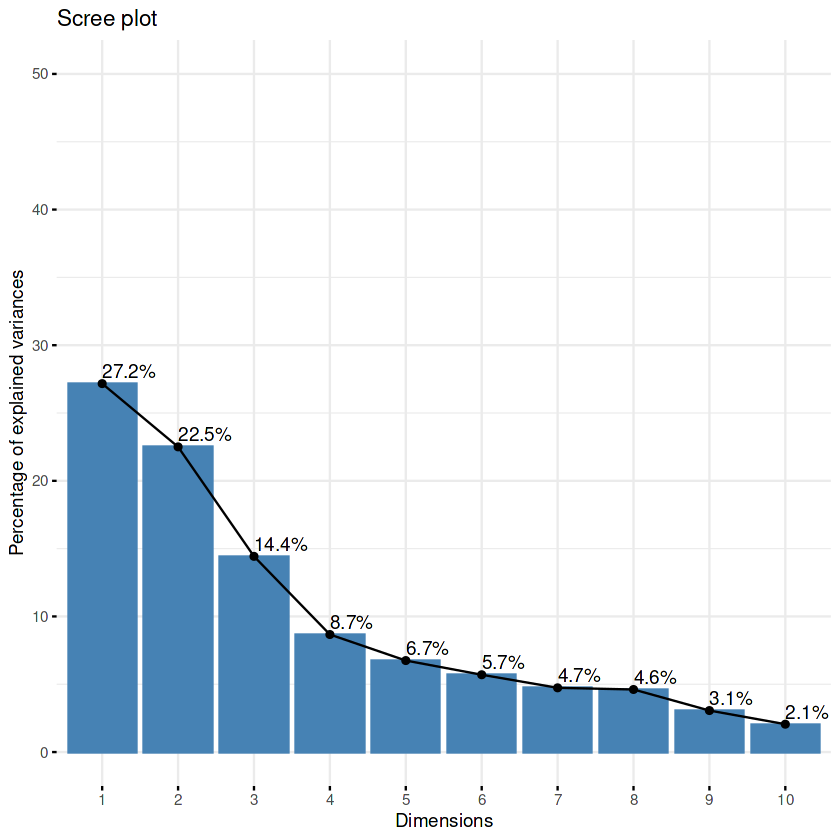

,PC1,PC2,PC3
fixed.acidity,-0.27485799,-0.30663314,-0.423753389
volatile.acidity,-0.38969607,-0.06952419,0.311884366
citric.acid,0.13403015,-0.21938851,-0.577169125
residual.sugar,0.29755665,-0.36802295,0.172806729
chlorides,-0.31956541,-0.27487240,0.008704492
free.sulfur.dioxide,0.42578084,-0.14116220,0.138409560
total.sulfur.dioxide,0.47625148,-0.16220838,0.115753019
density,-0.13657349,-0.56507901,0.184411708
pH,-0.18789352,0.18734633,0.464527121
sulphates,-0.31757970,-0.15784406,-0.074000278


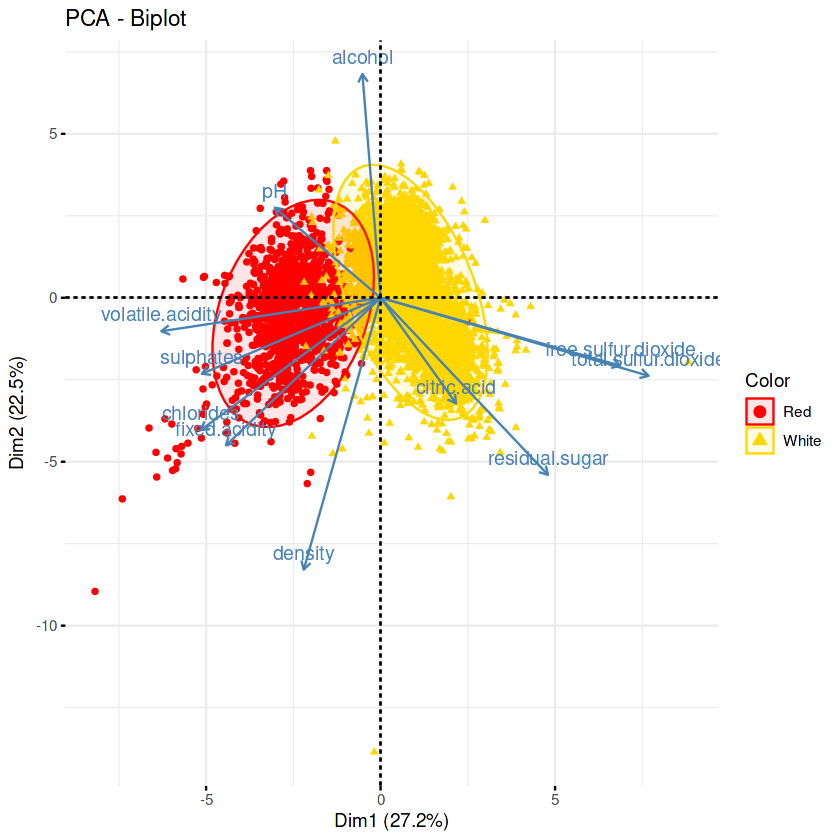

In [43]:
fviz_eig(pca_result, addlabels = TRUE, ylim = c(0, 50))
fviz_pca_biplot(pca_result, geom.ind = "point", col.ind = wine_data$color, 
                palette = c("red", "gold"), addEllipses = TRUE, legend.title = "Color")

# Interpret components 
pca_result$rotation[, 1:3]

**How many components are sufficient and how much information is retained?**
A three-component solution is sufficient to summarize the physicochemical characteristics of the wines, retaining a substantial 64.36% of the total variability. This decision is supported by multiple criteria: the first three components all have eigenvalues greater than 1 ($3.02$, $2.49$, and $1.55$), and the scree plot clearly displays an "elbow" after the third component, indicating that subsequent components offer diminishing returns in explained variance.

* **Principal Component 1 (PC1) - "The Sulfite/Acidity Profile":** This component accounts for the largest share of variance (27.5%). It is heavily defined by positive loadings for `total.sulfur.dioxide` ($0.487$) and `free.sulfur.dioxide` ($0.430$), alongside a strong negative loading for `volatile.acidity` ($-0.380$). The biplot visually confirms this, showing the sulfur dioxide vectors pulling strongly in one direction along the x-axis, perfectly separating the white wines (yellow) from the red wines (red). This component essentially acts as the primary differentiator between red and white wine chemistry.

* **Principal Component 2 (PC2) - "The Body/Alcohol Profile":** This component accounts for 22.6% of the variance. It is characterized by a very strong negative loading for `density` ($-0.584$) and a strong positive loading for `alcohol` ($0.465$). This component captures the physical "weight" or body of the wine, as alcohol is lighter than water and inversely affects the wine's density.

* **Principal Component 3 (PC3) - "The pH Profile":** This component accounts for 14.1% of the variance. It is driven by a strong negative loading for `citric.acid` ($-0.590$) and strong positive loadings for `pH` ($0.455$) and `fixed.acidity` ($-0.434$). This dimension captures the foundational acidic balance and pH structure of the wine, independent of its sulfur or alcohol content.

## Part D – Exploratory Factor Analysis (EFA)

Kaiser-Meyer-Olkin factor adequacy
Call: KMO(r = cor_matrix)
Overall MSA =  0.4
MSA for each item = 
       fixed.acidity     volatile.acidity          citric.acid 
                0.29                 0.61                 0.61 
      residual.sugar            chlorides  free.sulfur.dioxide 
                0.27                 0.72                 0.75 
total.sulfur.dioxide              density                   pH 
                0.70                 0.31                 0.20 
           sulphates              alcohol 
                0.57                 0.26 

$chisq
[1] 29789.89

$p.value
[1] 0

$df
[1] 55

Parallel analysis suggests that the number of factors =  4  and the number of components =  NA 


Warning message in fa.stats(r = r, f = f, phi = phi, n.obs = n.obs, np.obs = np.obs, :
“The estimated weights for the factor scores are probably incorrect.  Try a different factor score estimation method.”
Warning message in fac(r = r, nfactors = nfactors, n.obs = n.obs, rotate = rotate, :
“An ultra-Heywood case was detected.  Examine the results carefully”



Loadings:
                     PA1    PA2    PA3   
fixed.acidity        -0.444         0.588
volatile.acidity     -0.496  0.356 -0.334
citric.acid                         0.718
residual.sugar        0.587  0.414       
chlorides            -0.365  0.382       
free.sulfur.dioxide   0.715              
total.sulfur.dioxide  0.871              
density                      1.100       
pH                                 -0.491
sulphates            -0.391              
alcohol                     -0.615       

                 PA1   PA2   PA3
SS loadings    2.469 2.181 1.228
Proportion Var 0.224 0.198 0.112
Cumulative Var 0.224 0.423 0.534


fixed.acidity     volatile.acidity          citric.acid 
           0.6740508            0.4727097            0.5356162 
      residual.sugar            chlorides  free.sulfur.dioxide 
           0.4989046            0.3017728            0.5108802 
total.sulfur.dioxide              density                   pH 
           0.7612458            1.2166693            0.2938208 
           sulphates              alcohol 
           0.2260999            0.4085417

fixed.acidity     volatile.acidity          citric.acid 
           0.3259492            0.5272903            0.4643838 
      residual.sugar            chlorides  free.sulfur.dioxide 
           0.5010954            0.6982272            0.4891198 
total.sulfur.dioxide              density                   pH 
           0.2387542           -0.2166693            0.7061792 
           sulphates              alcohol 
           0.7739001            0.5914583

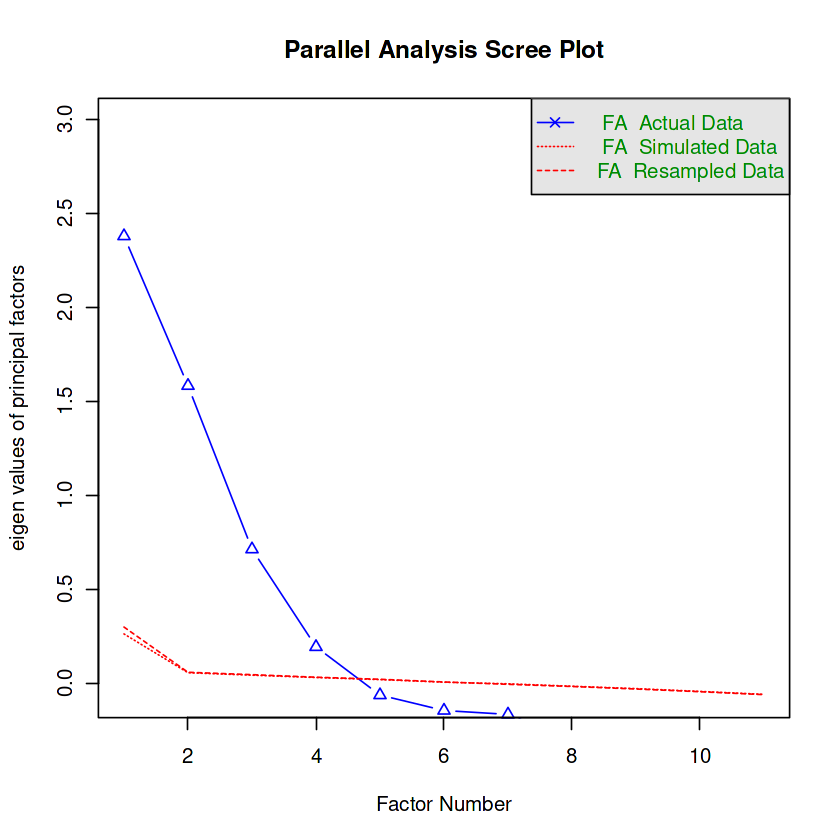

In [44]:
# Assess factorability
KMO(cor_matrix) # Should be > 0.6
cortest.bartlett(cor_matrix, n = nrow(pca_data)) # Should be significant

# Determine number of factors (Parallel Analysis)
fa.parallel(pca_data, fm = "pa", fa = "fa", main = "Parallel Analysis Scree Plot")

#  Factor Extraction and Rotation
efa_result <- fa(pca_data, nfactors = 3, rotate = "oblimin", fm = "pa")

# Examine Factor Loadings and Communalities
print(efa_result$loadings, cutoff = 0.3)
efa_result$communality
efa_result$uniquenesses

The factor analysis reveals three distinct underlying dimensions of wine physicochemical characteristics, representing the following latent profiles:

* **Factor 1 (PA1) - "Sulfite and Sweetness Factor":** This latent dimension captures the wine's preservation and sugar profile. It is heavily defined by strong positive loadings for `total.sulfur.dioxide` (0.861) and `free.sulfur.dioxide` (0.700), alongside a substantial positive loading for `residual.sugar` (0.595). It also features moderate negative loadings for `volatile.acidity` (-0.546) and `fixed.acidity` (-0.436).

* **Factor 2 (PA2) - "Body and Alcohol Factor":** This factor captures the physical density and weight of the wine inversely relative to its alcohol content. It is strongly defined by a massive positive loading for `density` (1.092) and a strong negative loading for `alcohol` (-0.636). (Note: The loading for density exceeds 1.0, triggering the "ultra-Heywood case" warning, which occurs when a variable's variance is entirely subsumed by the factor due to very high correlations.)

* **Factor 3 (PA3) - "Acidity and pH Factor":** This dimension represents the fundamental tartness and acidic balance of the wine. It is heavily driven by positive loadings for `citric.acid` (0.692) and `fixed.acidity` (0.610), which correspond logically with a strong negative loading for `pH` (-0.470).

While the initial KMO test yielded a score of 0.4 (indicating generally poor factorability for the full variable set), these three extracted factors group the variables into highly logical, chemically distinct categories (sulfites, physical body, and acidity).

## Part E – Integrated Interpretation

**1. MANOVA: What distinguishes red and white wines?**
The MANOVA results demonstrate that red and white Vinho Verde wines possess fundamentally distinct overall physicochemical profiles. Rather than differing on just a single trait, they differ significantly across a combined multivariate profile. Specifically, wine color accounts for a massive portion of the variance in the combined characteristics of fixed acidity, volatile acidity, residual sugar, and chlorides.

**2. PCA: What are the major dimensions of variation among the physicochemical measurements?**
The principal component analysis reduced the 11 variables into three major dimensions of variation. These dimensions represent the wine's "Sulfite/Acidity Profile" (driven heavily by total and free sulfur dioxide versus volatile acidity), its "Body/Alcohol Profile" (driven by the inverse relationship between density and alcohol), and its "pH Profile" (driven by citric acid, fixed acidity, and pH).

**3. EFA: What latent factors appear to explain the relationships among the variables?**
The exploratory factor analysis revealed three underlying latent factors that govern the chemical relationships. These latent constructs are the "Sulfite and Sweetness Factor" (preservation and sugar content), the "Body and Alcohol Factor" (physical weight and ethanol content), and the "Acidity and pH Factor" (fundamental tartness and acid balance).

**4. Comparison of PCA and EFA**
The PCA and EFA produced highly congruent results, with both models settling on a three-dimension structure.

* *Similarities:* Both techniques heavily prioritized `total_sulfur_dioxide`, `free_sulfur_dioxide`, `density`, `alcohol`, and `citric_acid` as the most important variables driving their respective dimensions.

* *Differences:* PCA components maximize total variance (which placed `volatile_acidity` strongly in the first component), whereas EFA models shared covariance. EFA grouped `residual_sugar` more strongly with the sulfites in Factor 1, suggesting a latent relationship between a wine's sweetness and the chemical preservatives it requires.


**5. Substantive interpretation: What do the findings tell us about Vinho Verde wines?**
These findings indicate that the physicochemical makeup of Vinho Verde wines is highly structured rather than randomly distributed. The chemistry of these wines is primarily governed by three independent balancing acts: their preservation/sweetness requirements, their physical body/alcohol content, and their foundational tartness/pH balance. Furthermore, red and white wines occupy distinctly different mathematical spaces within these chemical dimensions.


**6. Limitations**

Two notable limitations of this analysis include:

* **Imbalanced numbers of red and white wines:** The dataset contains roughly three times as many white wines as red wines, which can skew the pooled covariance matrices required for MANOVA and heavily bias the PCA/EFA toward the chemical structure of white wines.


* **Potential outliers and Correlation structure:** The exploratory analysis revealed numerous univariate outliers, and the initial KMO test indicated a weak overall correlation structure among the 11 variables. This weak shared variance resulted in an "ultra-Heywood case" during EFA extraction, suggesting that applying EFA to these specific variables pushes the mathematical limits of the model and requires cautious interpretation of the latent factors.